In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True, cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
from scipy import stats
import pandas as pd
import nibabel as nib
from tqdm import tqdm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import statsmodels.api as sm

import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({
    'font.size':         8,
    'figure.dpi':        300,
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Roboto'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

import seaborn as sns
from brainsmash.mapgen.base import Base

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])
sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/nctpy/src'])

from src.plotting import plot_repeated_measures_violins, plot_subject_level_violins
from src.notebook import load_notebook_data

from src.timescales import create_ints_dataframe_custom_grouping, convert_data_dict, average_data_dict_converted, compute_deflections_glm
from snaplab_tools.plotting.plotting import plot_correlation, plot_correlation_unity, plot_brain_surface_data
from snaplab_tools.plotting.utils import get_my_colors
from snaplab_tools.stats import steiger_test
from snaplab_tools.utils import winsorize

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [2]:
import pandas as pd
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import adjustText

In [3]:
my_colors = get_my_colors(cat_trio=False, as_list=True)

In [4]:
def average_pet_markers(df_neuro, pet_categories, pet_category='neurotransmitter_function'):
    unique_markers = pet_categories[pet_category].unique()
    df_out = pd.DataFrame()

    for i, marker in enumerate(unique_markers):
        mask = pet_categories[pet_category] == unique_markers[i]
        df_out[f'Mean_{marker}'] = np.nanmean(df_neuro.loc[:, pet_categories.index].iloc[:, mask.values], axis=1)
        # df_out[f'Median_{marker}'] = np.nanmedian(df_neuro.loc[:, pet_categories.index].iloc[:, mask.values], axis=1)

    return df_out

In [5]:
def compute_stat(x, y, method):
    """Compute correlation or R² and parametric p-value."""
    if method == 'pearson':
        r, p = sp.stats.pearsonr(x, y)
        return r, p
    elif method == 'spearman':
        r, p = sp.stats.spearmanr(x, y)
        return r, p
    elif method == 'r2':
        # Fit linear regression using sklearn
        X = x.reshape(-1, 1)
        model = LinearRegression()
        model.fit(X, y)
        y_pred = model.predict(X)
        r2 = r2_score(y, y_pred)
        
        # F-test for significance: F = (R² / k) / ((1 - R²) / (n - k - 1))
        # where k=1 (one predictor)
        n = len(x)
        if r2 == 1.0:
            p = 0.0
        elif r2 < 0:
            # R² can be negative if the model is worse than horizontal line
            p = 1.0
        else:
            f_stat = (r2 * (n - 2)) / (1 - r2)
            p = 1 - f.cdf(f_stat, 1, n - 2)
        
        return r2, p


def correlate_dataframes(df_neuro, df_ints, method='pearson', alpha=0.05, null_distributions=None):
    """
    Correlate every column in df_neuro with every column in df_ints.
    
    Parameters
    ----------
    df_neuro : pd.DataFrame
        First dataframe (regions × features)
    df_ints : pd.DataFrame
        Second dataframe (regions × features)
    method : str, default='pearson'
        Correlation method: 'pearson', 'spearman', or 'r2'
        - 'pearson': Pearson correlation coefficient
        - 'spearman': Spearman rank correlation
        - 'r2': Coefficient of determination (variance explained) using sklearn linear regression
    alpha : float, default=0.05
        Significance threshold
    null_distributions : dict, optional
        Dictionary with keys as df_ints column names and values as numpy arrays
        of shape [n_perms, n_regions] containing permuted null distributions.
        If provided, must contain all df_ints columns.
        Permutation p-values are one-sided based on the sign of the observed effect.
        
    Returns
    -------
    df_results : pd.DataFrame
        Correlation coefficients (or R²) with df_neuro columns as rows, df_ints columns as columns
    df_pvals : pd.DataFrame
        P-values with same structure as df_results
    """
    if len(df_neuro) != len(df_ints):
        raise ValueError(f"DataFrames must have same number of rows. Got {len(df_neuro)} and {len(df_ints)}")
    
    if method not in ['pearson', 'spearman', 'r2']:
        raise ValueError(f"method must be 'pearson', 'spearman', or 'r2', got '{method}'")
    
    # Validate null_distributions if provided
    if null_distributions is not None:
        missing_cols = set(df_ints.columns) - set(null_distributions.keys())
        extra_cols = set(null_distributions.keys()) - set(df_ints.columns)
        
        if missing_cols:
            raise ValueError(f"null_distributions missing columns: {missing_cols}")
        if extra_cols:
            raise ValueError(f"null_distributions contains extra columns not in df_ints: {extra_cols}")
        
        # Validate shapes
        for col, null_array in null_distributions.items():
            if null_array.shape[1] != len(df_ints):
                raise ValueError(
                    f"null_distributions['{col}'] has shape {null_array.shape}, "
                    f"but expected [n_perms, {len(df_ints)}]"
                )
    
    use_permutation = null_distributions is not None
    results = []
    pvals = []
    
    for neuro_col in df_neuro.columns:
        row_corrs = []
        row_pvals = []
        
        for int_col in df_ints.columns:
            # Get data with pairwise deletion
            mask = ~(df_neuro[neuro_col].isna() | df_ints[int_col].isna())
            x = df_neuro.loc[mask, neuro_col].values.astype(float)
            y = df_ints.loc[mask, int_col].values.astype(float)
            
            if len(x) < 3:  # Need at least 3 points for correlation
                row_corrs.append(np.nan)
                row_pvals.append(np.nan)
                continue
            
            # Compute observed statistic
            stat_obs, p_parametric = compute_stat(x, y, method)
            row_corrs.append(stat_obs)
            
            # Compute p-value
            if use_permutation:
                # Use permutation-based p-value
                null_array = null_distributions[int_col]
                n_perms = null_array.shape[0]
                
                # Apply same mask to all permutations
                null_masked = null_array[:, mask]
                
                # Compute statistic for each permutation
                perm_stats = np.zeros(n_perms)
                for i in range(n_perms):
                    y_perm = null_masked[i, :]
                    stat_perm, _ = compute_stat(x, y_perm, method)
                    perm_stats[i] = stat_perm
                
                # One-sided p-value based on sign of observed effect
                if method == 'r2':
                    # For R², always test if perm_r2 >= obs_r2 (R² is non-negative)
                    p_value = np.mean(perm_stats >= stat_obs)
                else:
                    # For correlations, one-sided based on direction
                    # p_value = np.mean(np.abs(perm_stats) >= np.abs(stat_obs))
                    if stat_obs >= 0:
                        p_value = np.mean(perm_stats >= stat_obs)
                    else:
                        p_value = np.mean(perm_stats <= stat_obs)
                
                row_pvals.append(p_value)
            else:
                # Use parametric p-value
                row_pvals.append(p_parametric)
        
        results.append(row_corrs)
        pvals.append(row_pvals)
    
    df_results = pd.DataFrame(results, index=df_neuro.columns, columns=df_ints.columns)
    df_pvals = pd.DataFrame(pvals, index=df_neuro.columns, columns=df_ints.columns)
    
    return df_results, df_pvals


def plot_correlation_lollipop(df_results, df_pvals, alpha=0.05, figsize=None, metric='correlation'):
    """
    Plot correlations as vertical lollipop plot grouped by df_neuro columns.
    Within each group, show paired lollipops for each df_ints column.
    
    Parameters
    ----------
    df_results : pd.DataFrame
        Correlation coefficients (or R²) (df_neuro cols × df_ints cols)
    df_pvals : pd.DataFrame
        P-values with same structure as df_results
    alpha : float, default=0.05
        Significance threshold for marking
    figsize : tuple, optional
        Figure size (width, height)
    metric : str, default='correlation'
        Type of metric being plotted: 'correlation' or 'r2'
    """
    # Reshape data for plotting
    plot_data = []
    for neuro_col in df_results.index:
        for int_col in df_results.columns:
            plot_data.append({
                'neuro_col': neuro_col,
                'int_col': int_col,
                'r': df_results.loc[neuro_col, int_col],
                'p': df_pvals.loc[neuro_col, int_col],
                'significant': df_pvals.loc[neuro_col, int_col] < alpha
            })
    
    plot_df = pd.DataFrame(plot_data)
    
    # Calculate positions - grouped by neuro_col, with int_cols within each group
    n_int_cols = len(df_results.columns)
    n_neuro_cols = len(df_results.index)
    gap_between_groups = 1.0
    spacing_within_group = 0.8
    
    positions = []
    x_labels = []
    group_centers = []
    
    current_pos = 0
    for i, neuro_col in enumerate(df_results.index):
        group_start = current_pos
        for j, int_col in enumerate(df_results.columns):
            positions.append(current_pos)
            x_labels.append(int_col)
            current_pos += spacing_within_group
        group_centers.append((group_start + current_pos - spacing_within_group) / 2)
        current_pos += gap_between_groups
    
    plot_df['x_pos'] = positions
    
    # Create figure
    if figsize is None:
        figsize = (max(12, n_neuro_cols * n_int_cols * 0.2), 6)
    
    fig, ax = plt.subplots(figsize=figsize)
    
    # Create color map for int_cols
    colors = plt.cm.tab10(np.linspace(0, 1, n_int_cols))
    int_col_colors = {col: colors[i] for i, col in enumerate(df_results.columns)}
    
    # Plot lollipops
    for idx, row in plot_df.iterrows():
        if np.isnan(row['r']):
            continue
            
        color = int_col_colors[row['int_col']]
        alpha_val = 1.0 if row['significant'] else 0.3
        
        # Stem
        ax.plot([row['x_pos'], row['x_pos']], [0, row['r']], 
                color=color, alpha=alpha_val, linewidth=2)
        # Circle
        ax.scatter(row['x_pos'], row['r'], color=color, alpha=alpha_val, 
                  s=80, zorder=3, edgecolors='black' if row['significant'] else 'none',
                  linewidths=1.5)
    
    # Add zero line
    ax.axhline(y=0, color='black', linewidth=0.8, linestyle='-', alpha=0.3)
    
    # Add vertical separators between groups
    for i in range(1, n_neuro_cols):
        sep_pos = i * (n_int_cols * spacing_within_group + gap_between_groups) - gap_between_groups / 2
        ax.axvline(x=sep_pos, color='gray', linewidth=1, linestyle='--', alpha=0.5)
    
    # Formatting
    ax.set_xlabel('INT Measures (grouped by conditions)', fontsize=12, fontweight='bold')
    
    if metric == 'r2':
        ax.set_ylabel('R² (Variance Explained)', fontsize=12, fontweight='bold')
        ax.set_title('Variance Explained between neurobiology and INTs', fontsize=14, fontweight='bold')
    else:
        ax.set_ylabel('Correlation Coefficient', fontsize=12, fontweight='bold')
        ax.set_title('Correlations between neurobiology and INTs', fontsize=14, fontweight='bold')
    
    # Set x-axis labels and ticks
    ax.set_xticks(positions)
    ax.set_xticklabels(x_labels, rotation=90, ha='right', fontsize=8)
    
    # Add group labels on secondary x-axis
    ax2 = ax.twiny()
    ax2.set_xlim(ax.get_xlim())
    ax2.set_xticks(group_centers)
    ax2.set_xticklabels(df_results.index, fontsize=10, fontweight='bold')
    ax2.tick_params(axis='x', which='both', length=0)
    
    # Standardize y-axis to show all correlations comparably
    if metric == 'r2':
        # R² ranges from 0 to 1
        ax.set_ylim(-0.05, max(1.0, ax.get_ylim()[1] * 1.05))
    else:
        y_max = max(abs(ax.get_ylim()[0]), abs(ax.get_ylim()[1]))
        ax.set_ylim(-y_max * 1.05, y_max * 1.05)
    
    # Add legend for int_cols
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='w', markerfacecolor=int_col_colors[col], 
               markersize=8, label=col, markeredgecolor='black')
        for col in df_results.columns
    ]
    legend_elements.append(
        Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
               markersize=8, label=f'p < {alpha}', markeredgecolor='black')
    )
    legend_elements.append(
        Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', 
               markersize=8, label='n.s.', alpha=0.3)
    )
    
    # ax.legend(handles=legend_elements, loc='lower right', fontsize=9, ncol=1)
    
    plt.tight_layout()
    
    return fig, ax

In [6]:
def plot_faceted_lollipops(
    df_r,
    df_p,
    category_colors=None,
    figsize=None,
    markersize=5,
    linewidth=1.2,
    alpha=1.0,
    nonsig_alpha=0.75,
    xlim=None,
    rank_reference="Rest",
    show_legend=True,
    annotate_sig=False,
    annotation_fontsize=5,
    annotation_offset=0.02,
    fontsize=8,
):
    """
    Horizontal faceted lollipop plot of correlations.
    One panel per column in df_r, with features sorted descending by r within each panel.
    Colors are assigned by feature category (prefix before first underscore in index).
    Category prefixes are stripped from y-tick labels since they appear in the legend.

    Significance thresholds are hardcoded:
        p >= 0.05  --> 'ns'
        p <  0.05  --> '*'
        p <  0.001 --> '**'

    Parameters
    ----------
    df_r : pd.DataFrame
        Correlation coefficients. Rows = features, columns = conditions.
    df_p : pd.DataFrame
        P-values matching df_r shape and labels.
    category_colors : dict, list, or None
        Maps category prefix (e.g. "Gene", "PET") to a matplotlib color.
        May also be a list of colors, assigned to unique categories in order.
        If None, colors are assigned automatically from tab10.
    figsize : tuple or None
        Figure size. If None, auto-computed from number of panels and features.
    markersize : float
    linewidth : float
    alpha : float
        Alpha for significant lollipops (p < 0.05).
    nonsig_alpha : float
        Alpha for non-significant lollipops (p >= 0.05).
    xlim : tuple or None
        (xmin, xmax) for all panels. If None, inferred symmetrically from data.
    rank_reference : str or None
        Column name to use as reference for sorting panels by Spearman rank
        correlation and for displaying rho in panel titles. If None or not found
        in df_r.columns, panels are shown in original column order with no rho
        annotations.
    show_legend : bool
        If True, show legend below the figure.
    annotate_sig : bool
        If True, annotate each lollipop tip with significance symbol.
    annotation_fontsize : float
        Font size for significance annotations.
    annotation_offset : float
        Horizontal offset from the marker tip for annotation placement.
    fontsize : int or float
        Base font size for axis labels, tick labels, titles, and legend.

    Returns
    -------
    fig : matplotlib.figure.Figure
    axes : list of matplotlib.axes.Axes
    """
    features = df_r.index.tolist()
    all_conditions = df_r.columns.tolist()

    rank_ref_active = False
    if rank_reference is not None:
        if rank_reference in all_conditions:
            rank_ref_active = True
        else:
            warnings.warn(
                f"rank_reference='{rank_reference}' not found in df_r columns "
                f"{all_conditions}. Panel ordering and rho annotations will be skipped.",
                UserWarning,
                stacklevel=2,
            )

    if rank_ref_active:
        other_conditions = [c for c in all_conditions if c != rank_reference]
        rhos = {
            c: scipy.stats.spearmanr(df_r[rank_reference], df_r[c])[0]
            for c in other_conditions
        }
        other_conditions_sorted = sorted(other_conditions, key=lambda c: rhos[c], reverse=True)
        conditions = [rank_reference] + other_conditions_sorted
    else:
        conditions = all_conditions

    n_conditions = len(conditions)
    n_features = len(features)

    categories = [f.split("_")[0] for f in features]
    unique_categories = list(dict.fromkeys(categories))

    if category_colors is None:
        cmap = matplotlib.colormaps["tab10"]
        category_colors = {cat: cmap(i) for i, cat in enumerate(unique_categories)}
    elif isinstance(category_colors, (list, tuple)):
        category_colors = {cat: category_colors[i] for i, cat in enumerate(unique_categories)}

    color_map = {f: category_colors[cat] for f, cat in zip(features, categories)}

    if xlim is None:
        absmax = np.nanmax(np.abs(df_r.values))
        bound = round(absmax + 0.15, 1)
        xlim = (-bound, bound)

    if figsize is None:
        panel_width = 2.8
        panel_height = max(4, n_features * 0.18)
        figsize = (panel_width * n_conditions, panel_height)

    fig, axes = plt.subplots(
        1, n_conditions,
        figsize=figsize,
        sharey=False,
        dpi=300,
    )
    if n_conditions == 1:
        axes = [axes]

    for ax, condition in zip(axes, conditions):
        r_vals = df_r[condition]
        p_vals = df_p[condition]

        order = r_vals.sort_values(ascending=False).index.tolist()
        y_positions = np.arange(len(order))

        for y, feature in zip(y_positions, order):
            r = r_vals[feature]
            p = p_vals[feature]
            color = color_map[feature]
            a = alpha if p < 0.05 else nonsig_alpha

            ax.hlines(y, 0, r, color=color, linewidth=linewidth, alpha=a)
            ax.plot(r, y, "o", color=color, markersize=markersize, alpha=a)

            if annotate_sig:
                if p < 0.001:
                    label = "**"
                elif p < 0.05:
                    label = "*"
                else:
                    label = "ns"
                x_offset = annotation_offset if r >= 0 else -annotation_offset
                ha = "left" if r >= 0 else "right"
                ax.text(
                    r + x_offset, y, label,
                    ha=ha, va="center",
                    fontsize=annotation_fontsize,
                    color=color,
                    alpha=a,
                )

        ax.axvline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.4)
        ax.set_xlim(xlim)
        ax.set_ylim(-0.8, len(order) - 0.2)
        ax.set_yticks(y_positions)
        stripped_labels = [f.split("_", 1)[1] if "_" in f else f for f in order]
        ax.set_yticklabels(stripped_labels, fontsize=fontsize - 1)

        if rank_ref_active and condition != rank_reference:
            rho, _ = scipy.stats.spearmanr(df_r[rank_reference], df_r[condition])
            title = f"{condition}\n$\\rho_{{rank}}$ = {rho:.2f} (vs. {rank_reference})"
        else:
            title = condition

        ax.set_title(title, fontsize=fontsize, fontweight="bold")
        ax.set_xlabel("Correlation", fontsize=fontsize - 1)
        ax.tick_params(axis="x", labelsize=fontsize - 1)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    legend_handles = [
        mpatches.Patch(color=category_colors[cat], label=cat)
        for cat in unique_categories
    ]
    if show_legend:
        leg = fig.legend(
            handles=legend_handles,
            loc="lower center",
            ncol=1,
            fontsize=fontsize - 1,
            frameon=False,
            bbox_to_anchor=(0.5, 0),
        )
        # Measure legend height and reserve that space at the bottom
        fig.canvas.draw()
        leg_height = leg.get_window_extent().height / fig.bbox.height
        fig.tight_layout(rect=[0, leg_height + 0.02, 1, 1])
    else:
        fig.tight_layout()

    return fig, axes

In [7]:
def _draw_lollipop(ax, plot_delta, sig_either, color_map, nonsig_color,
                   linewidth, markersize, sig_alpha, nonsig_alpha,
                   absolute_delta, delta_label, delta_title, xlim, fontsize):
    """Draw a single horizontal lollipop panel onto ax."""
    order = plot_delta.sort_values(ascending=False).index.tolist()
    y_positions = np.arange(len(order))

    for y, feature in zip(y_positions, order):
        dr = plot_delta[feature]
        sig = sig_either[feature]
        color = color_map[feature] if sig else nonsig_color
        alpha = sig_alpha if sig else nonsig_alpha

        ax.hlines(y, 0, dr, color=color, linewidth=linewidth, alpha=alpha)
        ax.plot(dr, y, "o", color=color, markersize=markersize, alpha=alpha)

    ax.axvline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.4)
    ax.set_xlim(xlim)
    ax.set_ylim(-0.8, len(order) - 0.2)
    ax.set_yticks(y_positions)
    stripped_labels = [f.split("_", 1)[1] if "_" in f else f for f in order]
    ax.set_yticklabels(stripped_labels, fontsize=fontsize - 1)
    ax.set_xlabel(delta_label, fontsize=fontsize - 1)
    ax.set_title(delta_title, fontsize=fontsize, fontweight="bold")
    ax.tick_params(axis="x", labelsize=fontsize - 1)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


def plot_two_condition_supplement(
    df_r,
    df_p,
    reference,
    sig_threshold=0.05,
    category_colors=None,
    figsize=None,
    markersize=5,
    linewidth=1.2,
    sig_alpha=1.0,
    nonsig_alpha=0.25,
    nonsig_color="#aaaaaa",
    annotate_scatter=False,
    annotation_fontsize=5,
    absolute_delta=False,
    show_lollipop=True,
    split_lollipop=False,
    show_legend=True,
    fontsize=8,
):
    """
    One-, two-, or three-panel supplementary figure for the two-condition case.
    Left panel: Scatter plot of r(reference) vs r(task).
    Right panel(s): Horizontal lollipop of delta_r (task - reference), sorted descending.
      Only shown if show_lollipop=True (default).
      If split_lollipop=True, the lollipop is split into two sub-panels:
        top    = features where r(reference) >= 0
        bottom = features where r(reference) <  0
      Sub-panel heights are proportional to the number of features in each.

    Features are greyed out only if non-significant in BOTH conditions.
    Colors are assigned by feature category (prefix before first underscore).
    Category prefixes are stripped from y-tick labels since they appear in the legend.

    Parameters
    ----------
    df_r : pd.DataFrame
        Correlation coefficients. Must have exactly 2 columns, one of which is `reference`.
    df_p : pd.DataFrame
        P-values matching df_r.
    reference : str
        Column name of the reference condition.
    sig_threshold : float
    category_colors : dict or None
        Maps category prefix (e.g. "Gene", "PET") to a matplotlib color.
        If None, colors are assigned automatically from tab10.
    figsize : tuple or None
        Figure size. If None, auto-computed from number of features.
    markersize : float
    linewidth : float
    sig_alpha : float
        Alpha for significant features.
    nonsig_alpha : float
        Alpha for non-significant features.
    nonsig_color : str
        Color applied to features non-significant in both conditions.
    annotate_scatter : bool
        If True, annotate each scatter point with the feature name (prefix stripped).
    annotation_fontsize : float
    absolute_delta : bool
        If True, plot |delta_r| instead of signed delta_r. Only used if show_lollipop=True.
    show_lollipop : bool
        If True, show lollipop panel(s) alongside the scatter. If False, only the
        scatter plot is shown and split_lollipop and absolute_delta are ignored.
    split_lollipop : bool
        If True, split lollipop into two sub-panels by sign of r(reference).
        Only used if show_lollipop=True.
    show_legend : bool
        If True, show legend below the figure.
    fontsize : int or float
        Base font size for axis labels, tick labels, titles, and legend. Default 8.

    Returns
    -------
    fig : matplotlib.figure.Figure
    axes : tuple of matplotlib.axes.Axes
        show_lollipop=False:              (ax_scatter,)
        show_lollipop=True, split=False:  (ax_scatter, ax_lollipop)
        show_lollipop=True, split=True:   (ax_scatter, ax_lollipop_pos, ax_lollipop_neg)
    """
    if df_r.shape[1] != 2:
        raise ValueError("plot_two_condition_supplement requires exactly 2 conditions.")
    if reference not in df_r.columns:
        raise ValueError(f"Reference '{reference}' not found in df_r columns.")

    task = [c for c in df_r.columns if c != reference][0]
    features = df_r.index.tolist()

    # Categories and colors
    categories = [f.split("_")[0] for f in features]
    unique_categories = list(dict.fromkeys(categories))

    if category_colors is None:
        cmap = matplotlib.colormaps["tab10"]
        category_colors = {cat: cmap(i) for i, cat in enumerate(unique_categories)}

    color_map = {f: category_colors[cat] for f, cat in zip(features, categories)}

    # Significance: grey out only if non-sig in BOTH conditions
    sig_ref = df_p[reference] < sig_threshold
    sig_task = df_p[task] < sig_threshold
    sig_either = sig_ref | sig_task

    # Figure and GridSpec
    if figsize is None:
        n_features = len(features)
        figsize = (12, max(4, n_features * 0.18)) if show_lollipop else (5, max(4, n_features * 0.18))

    fig = plt.figure(figsize=figsize, dpi=300)

    if not show_lollipop:
        ax_scatter = fig.add_subplot(1, 1, 1)
        lollipop_axes = []
    elif not split_lollipop:
        gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1, 0.33])
        ax_scatter = fig.add_subplot(gs[0, 0])
        ax_lollipop = fig.add_subplot(gs[0, 1])
        lollipop_axes = [ax_lollipop]
    else:
        pos_features = df_r.index[df_r[reference] >= 0].tolist()
        neg_features = df_r.index[df_r[reference] < 0].tolist()

        gs = gridspec.GridSpec(1, 3, figure=fig, width_ratios=[2, 1, 1])
        ax_scatter = fig.add_subplot(gs[0, 0])
        ax_lollipop_neg = fig.add_subplot(gs[0, 1])
        ax_lollipop_pos = fig.add_subplot(gs[0, 2])
        lollipop_axes = [ax_lollipop_neg, ax_lollipop_pos]

    # Draw lollipop panel(s) if requested
    if show_lollipop:
        delta_r = df_r[task] - df_r[reference]
        plot_delta = delta_r.abs() if absolute_delta else delta_r
        delta_label = (
            f"|\u0394r|  (|{task} \u2212 {reference}|)"
            if absolute_delta
            else f"\u0394r  ({task} \u2212 {reference})"
        )
        delta_title_base = (
            f"Absolute change\n(|{task} \u2212 {reference}|)"
            if absolute_delta
            else f"Change in correlation\n({task} \u2212 {reference})"
        )
        lollipop_xlim = (
            -0.05 if absolute_delta else min(-0.1, plot_delta.min() - 0.05),
            max(0.1, plot_delta.max() + 0.05),
        )

        lollipop_subsets = (
            [(plot_delta, delta_title_base)]
            if not split_lollipop
            else [
                (plot_delta.loc[neg_features], f"r({reference}) < 0"),
                (plot_delta.loc[pos_features], f"r({reference}) \u2265 0"),
            ]
        )

        for ax_l, (subset_delta, title) in zip(lollipop_axes, lollipop_subsets):
            _draw_lollipop(
                ax_l, subset_delta, sig_either, color_map, nonsig_color,
                linewidth, markersize, sig_alpha, nonsig_alpha,
                absolute_delta, delta_label, title, lollipop_xlim, fontsize,
            )

    # Scatter panel
    absmax = max(np.abs(df_r.values).max(), 0.1)
    bound = round(absmax + 0.05, 1)
    ax_scatter.set_xlim(-bound, bound)
    ax_scatter.set_ylim(-bound, bound)

    texts = []
    x_coords = []
    y_coords = []
    for feature in features:
        r_ref = df_r.loc[feature, reference]
        r_task = df_r.loc[feature, task]
        sig = sig_either[feature]
        color = color_map[feature] if sig else nonsig_color
        alpha = sig_alpha if sig else nonsig_alpha

        ax_scatter.plot(r_ref, r_task, "o", color=color, markersize=markersize, alpha=alpha)
        x_coords.append(r_ref)
        y_coords.append(r_task)

        if annotate_scatter:
            label = "_".join(feature.split("_")[1:])
            texts.append(ax_scatter.text(
                r_ref, r_task, label,
                fontsize=annotation_fontsize,
                color=color,
                alpha=alpha,
            ))

    if annotate_scatter and texts:
        adjustText.adjust_text(
            texts,
            x=x_coords,
            y=y_coords,
            ax=ax_scatter,
            expand=(1.5, 2.0),
            force_text=(0.5, 1.0),
            force_points=(0.5, 1.0),
            ensure_inside_axes=True,
            arrowprops=dict(arrowstyle="-", color="grey", lw=0.4, alpha=0.5),
        )

    ax_scatter.plot([-bound, bound], [-bound, bound], color="black", linewidth=0.7,
                    linestyle="--", alpha=0.4)
    ax_scatter.axhline(0, color="grey", linewidth=0.4, alpha=0.3)
    ax_scatter.axvline(0, color="grey", linewidth=0.4, alpha=0.3)
    ax_scatter.set_xlabel(f"r  ({reference})", fontsize=fontsize - 1)
    ax_scatter.set_ylabel(f"r  ({task})", fontsize=fontsize - 1)
    ax_scatter.set_title(f"{reference} vs. {task}", fontsize=fontsize, fontweight="bold")
    ax_scatter.tick_params(labelsize=fontsize - 1)
    ax_scatter.set_aspect("equal", adjustable="box")
    ax_scatter.spines["top"].set_visible(False)
    ax_scatter.spines["right"].set_visible(False)

    # Legend handles
    legend_handles = [
        mpatches.Patch(color=category_colors[cat], label=cat)
        for cat in unique_categories
    ]
    legend_handles.append(
        mpatches.Patch(color=nonsig_color, alpha=nonsig_alpha,
                       label=f"p >= {sig_threshold} (both conditions)")
    )

    fig.tight_layout()

    # If split_lollipop, match lollipop panel heights to the rendered scatter plot height
    if show_lollipop and split_lollipop:
        fig.canvas.draw()
        scatter_bbox = ax_scatter.get_position()
        scatter_height = scatter_bbox.height
        scatter_y0 = scatter_bbox.y0

        for ax_l in lollipop_axes:
            pos = ax_l.get_position()
            ax_l.set_position([pos.x0, scatter_y0, pos.width, scatter_height])

    if show_legend:
        fig.canvas.draw()
        renderer = fig.canvas.get_renderer()
        fig_height_px = fig.get_size_inches()[1] * fig.dpi
        all_axes = [ax_scatter] + list(lollipop_axes)
        min_bottom_px = min(ax.get_tightbbox(renderer).y0 for ax in all_axes)
        min_bottom_fig = min_bottom_px / fig_height_px
        fig.legend(
            handles=legend_handles,
            loc="upper center",
            ncol=len(legend_handles),
            fontsize=fontsize - 1,
            frameon=False,
            bbox_to_anchor=(0.5, min_bottom_fig - 0.01),
        )

    if not show_lollipop:
        return fig, (ax_scatter,)
    elif not split_lollipop:
        return fig, (ax_scatter, ax_lollipop)
    else:
        return fig, (ax_scatter, ax_lollipop_pos, ax_lollipop_neg)

# Load data

In [8]:
dataset = 'HCP-YA'
which_modality = 'FMRI'
# meg_freq = '_lp-0.5hz'
use_7t = False
# output_type = 'timescale_zero_crossing'
# output_type = 'timescale_zero_crossing_robust_nc3'
output_type = 'timescale_auc_zero_crossing'

# output_type = output_type + '_lp-0.01hz'
# output_type = output_type + '_hp-0.01hz'
# output_type = output_type + '_bp-0.01-0.08hz'
# output_type = output_type + '_bp-0.08-0.15hz'

notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   use_7t=use_7t, output_type=output_type,
                                   load_subject_data=False)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-YA
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/HCP_1200
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_YA/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       1206 subjects

	Initialized Timescales for dataset: HCP-YA
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 15456 scans from scan_registry_HCP-YA.csv


Loading metric_tsnr: 100%|██████████| 15456/15456 [00:01<00:00, 7769.30it/s]


15456
timescale_auc_zero_crossing


Loading timescale_auc_zero_crossing: 100%|██████████| 15456/15456 [00:01<00:00, 8142.69it/s]


15456


Loading timescale_auc_zero_crossing_resids: 100%|██████████| 15456/15456 [00:01<00:00, 8279.63it/s]

15456
Number of subjects: 966


In [9]:
left_hemi = False

In [10]:
nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/{dataset}'
if not os.path.exists(nas_scratch_dir):
    os.mkdir(nas_scratch_dir)

In [11]:
# get key outputs for this notebook
timescales_processor = notebook_data['timescales_processor']
data_dict = notebook_data['data_dict']
data_dict_tsnr = notebook_data['data_dict_tsnr']
results_dir = notebook_data['results_dir']

df_neuro = notebook_data['supporting_data']['df_neuro'].copy()
pet_categories = notebook_data['supporting_data']['pet_categories']
distance_matrix = notebook_data['supporting_data']['distance_matrix']
gene_expression_nanmask = notebook_data['supporting_data']['gene_expression_nanmask']
yeo_systems = notebook_data['supporting_data']['yeo_systems']

pca_results_pet = notebook_data['supporting_data']['pca_results_pet']

if left_hemi:
    df_neuro = df_neuro.iloc[:200, :] # retain left hemi
    yeo_systems = yeo_systems[:200]

print(data_dict.keys())
print(df_neuro.shape, df_neuro.columns)

dict_keys(['sub-100206_task-rfMRIREST1LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST1RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2LR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-rfMRIREST2RL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-rest', 'sub-100206_task-tfMRIWMLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIWMRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIEMOTIONRL_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGLR_space-fsLR_seg-Schaefer4007_ses-01_modality-MRI3T_tr-0.72_condition-task', 'sub-100206_task-tfMRIGAMBLINGRL_space-fsLR

# Data for figures

In [12]:
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs = len(subject_ids)
print(f'Number of subjects: {n_subs}')

Number of subjects: 966


## PET data

In [13]:
pet_categories.head()

,neurotransmitter_function,monoamine_status,receptor_mechanism,gpcr_signaling,custom_grouping
PET,,,,,
PET_5HT1a,Inhibitory,Monoamine,Metabotropic,Gi,Gi
PET_5HT1b,Inhibitory,Monoamine,Metabotropic,Gi,Gi
PET_5HT2a,Excitatory,Monoamine,Metabotropic,Gq,Gq
PET_5HT4,Excitatory,Monoamine,Metabotropic,Gs,Gs
PET_5HT6,Excitatory,Monoamine,Metabotropic,Gs,Gs


In [14]:
pet_categories.to_csv(os.path.join(nas_scratch_dir, 'pet_categories.csv'))

In [15]:
pet_category = 'neurotransmitter_function'
# pet_category = 'monoamine_status'
# pet_category = 'receptor_mechanism'
# pet_category = 'gpcr_signaling'
# pet_category = 'custom_grouping'

plot_cols = pet_categories[pet_category].unique()
plot_cols = [f'Mean_{s}' for s in plot_cols]

if pet_category == 'neurotransmitter_function':
    order_indices = [1, 0, 2]
    plot_cols = [plot_cols[i] for i in order_indices]

if pet_category == 'receptor_mechanism':
    order_indices = [0, 2, 1]
    plot_cols = [plot_cols[i] for i in order_indices]

print(plot_cols)

['Mean_Excitatory', 'Mean_Inhibitory', 'Mean_Transporter']


In [16]:
# hold onto SA axis
sa_axis = df_neuro['SA_Axis'].copy()

# PET only
neuro_cols = pet_categories.index
print(list(neuro_cols))
df_neuro = df_neuro[neuro_cols]
for col in neuro_cols:
    df_neuro[col] = sp.stats.zscore(df_neuro[col])

neuro_cols = [s.split('_')[1] for s in neuro_cols] # remove PET prefix
neuro_cols = ['_'.join(s) for s in zip(*[list(pet_categories[pet_category]), neuro_cols])] # append PET category

print(neuro_cols)
df_neuro.columns = neuro_cols
pet_categories.index = neuro_cols

['PET_5HT1a', 'PET_5HT1b', 'PET_5HT2a', 'PET_5HT4', 'PET_5HT6', 'PET_5HTT', 'PET_A4B2', 'PET_CB1', 'PET_D1', 'PET_D2', 'PET_DAT', 'PET_GABAa', 'PET_H3', 'PET_M1', 'PET_mGluR5', 'PET_MOR', 'PET_NET', 'PET_NMDA', 'PET_VAChT']
['Inhibitory_5HT1a', 'Inhibitory_5HT1b', 'Excitatory_5HT2a', 'Excitatory_5HT4', 'Excitatory_5HT6', 'Transporter_5HTT', 'Excitatory_A4B2', 'Inhibitory_CB1', 'Excitatory_D1', 'Inhibitory_D2', 'Transporter_DAT', 'Inhibitory_GABAa', 'Inhibitory_H3', 'Excitatory_M1', 'Excitatory_mGluR5', 'Inhibitory_MOR', 'Transporter_NET', 'Excitatory_NMDA', 'Transporter_VAChT']


In [17]:
# df_neuro = df_neuro.rename(columns={"SA_Axis": "Hierarchy_SA-Axis", "SF_Axis": "Hierarchy_SF-Axis", "Micro_Axis": "Hierarchy_Micro-Axis"})
# df_neuro.drop(['Gene_PC1', 'Gene_PC2', 'Gene_PC3', 'PET_PC1', 'PET_PC2', 'PET_PC3'], axis=1, inplace=True)
df_tmp = average_pet_markers(df_neuro, pet_categories, pet_category)
df_neuro = pd.concat((df_neuro, df_tmp), axis=1)
df_neuro.to_csv(os.path.join(nas_scratch_dir, 'df_neuro.csv'))
df_neuro

,Inhibitory_5HT1a,Inhibitory_5HT1b,Excitatory_5HT2a,Excitatory_5HT4,Excitatory_5HT6,Transporter_5HTT,Excitatory_A4B2,Inhibitory_CB1,Excitatory_D1,Inhibitory_D2,...,Inhibitory_H3,Excitatory_M1,Excitatory_mGluR5,Inhibitory_MOR,Transporter_NET,Excitatory_NMDA,Transporter_VAChT,Mean_Inhibitory,Mean_Excitatory,Mean_Transporter
0,1.614237,-1.551524,-0.622990,-0.332484,-0.402850,-0.148633,0.111111,0.405421,1.377349,0.664718,...,-0.280807,-1.452824,-0.222367,0.165875,-0.591126,0.665970,-0.191840,0.228763,-0.109886,-0.012782
1,3.305001,-1.909693,-0.477938,0.115878,0.054898,1.102549,-0.374434,0.743488,1.181265,1.431553,...,-0.379831,0.002905,0.500693,-0.119417,-0.622328,0.241969,0.157440,0.503121,0.155654,0.520375
2,0.698153,-0.827148,-0.612888,-0.605931,-0.069260,-0.535546,0.516099,0.442204,0.247319,-0.064984,...,-0.295113,-1.381489,-0.549766,-0.531764,-0.008628,0.935856,-0.276512,0.001680,-0.190008,-0.070570
3,-0.110659,-0.721145,-0.180204,-0.180539,0.195876,0.446339,0.219247,-0.181284,1.036256,0.116494,...,-0.612207,-0.405848,-0.044645,-0.966043,-0.060369,1.162613,-0.180475,-0.149519,0.225345,0.198754
4,-0.863915,-0.438107,-0.419356,-0.535125,0.205776,-0.083110,0.331499,-0.405958,0.557038,-0.241343,...,-0.572249,-0.606494,-0.716760,-1.623782,0.070676,0.987789,-0.537521,-0.404305,-0.024454,0.040323
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.154053,0.836156,1.132890,0.932261,1.982135,0.063303,0.895141,0.120724,1.637984,-0.180128,...,0.749352,1.674992,1.960659,-0.117565,0.629061,1.737148,0.175494,0.500103,1.494151,0.334828
396,0.240357,-0.002384,1.301539,1.097546,0.374291,0.713361,0.792788,-0.464514,1.958279,-0.533133,...,-0.174779,-0.208275,1.201117,0.612511,0.003110,1.149841,0.698985,0.172409,0.958391,0.573407
397,0.633451,0.207199,1.196689,1.127245,-0.419430,1.409967,1.006725,-0.096383,1.944954,-0.373326,...,0.688426,-0.256138,1.721952,1.141730,0.555628,1.045782,2.071048,0.527279,0.920972,1.249014
398,-0.380726,-0.231245,1.122860,0.841824,0.755705,-0.005936,0.679539,-0.335587,1.091462,-0.457215,...,0.048936,0.370358,0.888286,0.088877,0.179896,1.180219,0.204367,-0.149285,0.866282,0.278466


## INT data

In [18]:
collapse_hcp = True
sort_by_median = True

if which_modality == 'FMRI' and 'HCP' in dataset:
    if collapse_hcp:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_all_rest=True, average_7t_movies=True, average_3t_tasks=True)
        df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, sort_by_median=sort_by_median,
                                                        average_all_rest=True, average_7t_movies=True, average_3t_tasks=True)
    else:
        df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median,
                                                        average_7t_rest=True, average_3t_rest=True, average_all_rest=False,
                                                        average_3t_task_pairs=True, average_7t_movies=True)
        df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, sort_by_median=sort_by_median,
                                                        average_7t_rest=True, average_3t_rest=True, average_all_rest=False,
                                                        average_3t_task_pairs=True, average_7t_movies=True)
else:
    df_ints = create_ints_dataframe_custom_grouping(data_dict, sort_by_median=sort_by_median)
    df_tsnr = create_ints_dataframe_custom_grouping(data_dict_tsnr, sort_by_median=sort_by_median)

if collapse_hcp:
    reference = 'task-Rest'
    condition = 'task-Tasks'
else:
    reference = 'task-REST_3T'
    condition = 'task-WM'

# filter out low-SNR regions
q = 0.1
region_mask = np.logical_or(df_tsnr[reference] < np.quantile(df_tsnr[reference], q=q),
                             df_tsnr[condition] < np.quantile(df_tsnr[condition], q=q))
region_mask = region_mask.values
for col in df_ints.columns:
    df_ints.loc[:, col][region_mask] = np.nan

if left_hemi:
    df_ints = df_ints.iloc[:200, :]

df_ints

,task-Rest,task-Tasks
0,1.213707,1.028889
1,1.560372,1.020117
2,1.835115,1.301449
3,1.684440,1.113178
4,2.396688,1.553311
...,...,...
395,3.191837,1.444041
396,2.215693,1.271652
397,1.459266,1.077343
398,2.647273,1.362698


## BrainSMASH spatial nulls

In [19]:
n_perms = 5000
null_dir = os.path.join(nas_scratch_dir, 'brainsmash_nulls')
os.makedirs(null_dir, exist_ok=True)

# Generate (or load) spatially autocorrelation-preserving nulls for every PET map.
# Nulls are saved as (n_perms, n_regions) arrays so they can be reloaded on future
# runs without re-running BrainSMASH.
brainsmash_nulls = {}
for col in tqdm(df_neuro.columns, desc='BrainSMASH nulls'):
    null_file = os.path.join(null_dir, f'{col}_{n_perms}_nulls.npy')
    if os.path.exists(null_file):
        brainsmash_nulls[col] = np.load(null_file)
    else:
        brain_map = df_neuro[col].values
        valid = ~np.isnan(brain_map)
        D = distance_matrix[np.ix_(valid, valid)]
        base = Base(brain_map[valid], D)
        surrogates = base(n=n_perms)  # (n_perms, n_valid_regions)
        nulls = np.full((n_perms, len(brain_map)), np.nan)
        nulls[:, valid] = surrogates
        np.save(null_file, nulls)
        brainsmash_nulls[col] = nulls

print('Done. Null shapes:', {k: v.shape for k, v in list(brainsmash_nulls.items())[:3]})


BrainSMASH nulls: 100%|██████████| 22/22 [00:00<00:00, 30.67it/s]

Done. Null shapes: {'Inhibitory_5HT1a': (5000, 400), 'Inhibitory_5HT1b': (5000, 400), 'Excitatory_5HT2a': (5000, 400)}


# Figure 3: brain plots of PET maps

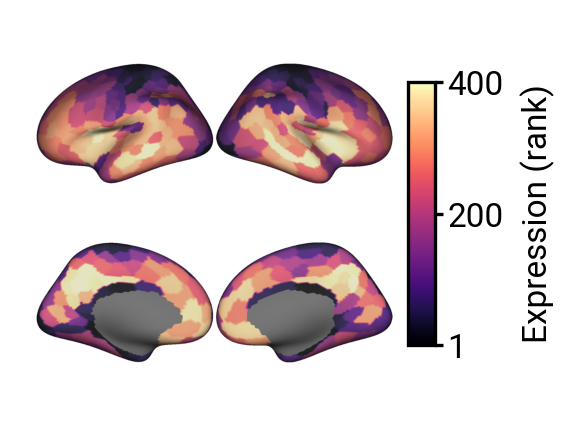

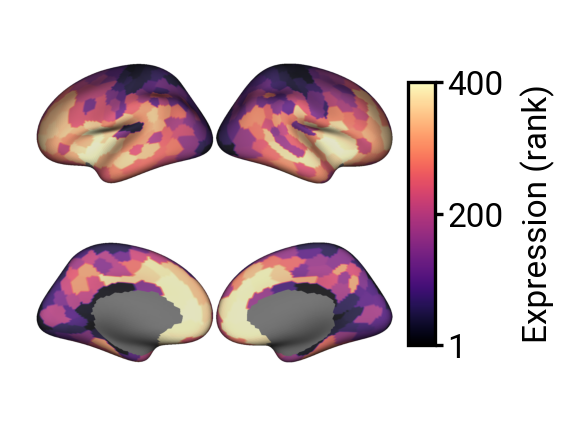

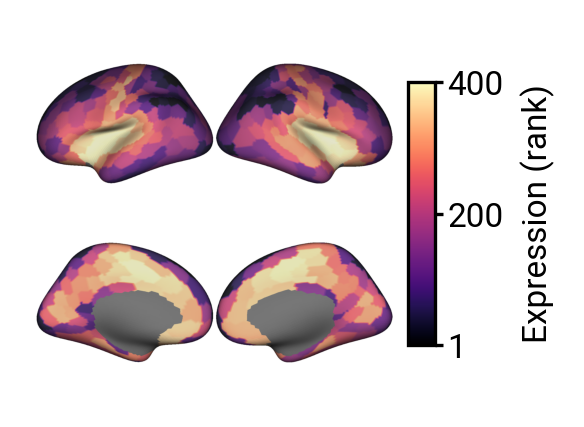

In [20]:
if not left_hemi:
    for col in plot_cols:
    # for col in df_neuro.columns:
        out_file = os.path.join(nas_scratch_dir, f'{col}.png')

        if 'PCA' in col:
            data_vector = df_neuro[col].values
            cmap = 'coolwarm'
            symmetric_cbar = True
            cbar_label = 'PC Score'
        else:
            data_vector = sp.stats.rankdata(df_neuro[col], nan_policy='omit').astype(int)
            cmap = 'magma'
            symmetric_cbar = False
            cbar_label = 'Expression (rank)'

        # if not os.path.exists(out_file):
        fig, axes = plot_brain_surface_data(
            data_vector=data_vector,
            parcellation='schaefer_400-7',
            # title=col.split('_')[1],
            title=None,
            cmap=cmap, symmetric_cbar=symmetric_cbar, cbar_label=cbar_label
        )
        plt.show()
        fig.savefig(os.path.join(nas_scratch_dir, f'{col}.png'), bbox_inches='tight', dpi=1000, transparent=True)
            
        # fig, axes = plt.subplots(nrows=1, ncols=1, sharex=False, sharey=False, figsize=(2.25, 1.75))
        # plot_correlation(sa_axis, data_vector, axes,
        #                  y_label=col,
        #                  data_group=np.asarray(yeo_systems), show_stats=True, fontsize=8, method='spearman',
        #                  size=15,
        #                  cbar_label='Yeo Systems',
        #                  auto_polynomial=True, models_to_test=[1,], model_selection_metric='variance_explained')
        # plt.show()

# Figure 3: Deflection correlation, scatter

In [21]:
df_neuro.head()

,Inhibitory_5HT1a,Inhibitory_5HT1b,Excitatory_5HT2a,Excitatory_5HT4,Excitatory_5HT6,Transporter_5HTT,Excitatory_A4B2,Inhibitory_CB1,Excitatory_D1,Inhibitory_D2,...,Inhibitory_H3,Excitatory_M1,Excitatory_mGluR5,Inhibitory_MOR,Transporter_NET,Excitatory_NMDA,Transporter_VAChT,Mean_Inhibitory,Mean_Excitatory,Mean_Transporter
0,1.614237,-1.551524,-0.622990,-0.332484,-0.402850,-0.148633,0.111111,0.405421,1.377349,0.664718,...,-0.280807,-1.452824,-0.222367,0.165875,-0.591126,0.665970,-0.191840,0.228763,-0.109886,-0.012782
1,3.305001,-1.909693,-0.477938,0.115878,0.054898,1.102549,-0.374434,0.743488,1.181265,1.431553,...,-0.379831,0.002905,0.500693,-0.119417,-0.622328,0.241969,0.157440,0.503121,0.155654,0.520375
2,0.698153,-0.827148,-0.612888,-0.605931,-0.069260,-0.535546,0.516099,0.442204,0.247319,-0.064984,...,-0.295113,-1.381489,-0.549766,-0.531764,-0.008628,0.935856,-0.276512,0.001680,-0.190008,-0.070570
3,-0.110659,-0.721145,-0.180204,-0.180539,0.195876,0.446339,0.219247,-0.181284,1.036256,0.116494,...,-0.612207,-0.405848,-0.044645,-0.966043,-0.060369,1.162613,-0.180475,-0.149519,0.225345,0.198754
4,-0.863915,-0.438107,-0.419356,-0.535125,0.205776,-0.083110,0.331499,-0.405958,0.557038,-0.241343,...,-0.572249,-0.606494,-0.716760,-1.623782,0.070676,0.987789,-0.537521,-0.404305,-0.024454,0.040323


In [22]:
results = compute_deflections_glm(df_ints.loc[:,reference], df_ints.loc[:,condition], df_neuro, standardize=True)

In [23]:
# For each PET map, compute a null distribution of correlations by:
#   1. Partialing rest INT out of each BrainSMASH surrogate map
#   2. Correlating the null feature partial residual with the observed task partial residual
# This preserves the spatial autocorrelation of the receptor maps under H0.
rest_vals = df_ints[reference].values

null_corrs = {}
for col in tqdm(df_neuro.columns, desc='Null correlations'):
    nulls      = brainsmash_nulls[col]          # (n_perms, n_regions)
    task_resid = results[col]['task_partial_resid']  # observed, (n_regions,)
    perm_r     = np.full(n_perms, np.nan)

    for i in range(n_perms):
        null_map = nulls[i]
        valid = ~(np.isnan(null_map) | np.isnan(rest_vals) | np.isnan(task_resid))
        if valid.sum() < 3:
            continue
        # partial out rest INT from the null receptor map
        X = sm.add_constant(rest_vals[valid])
        null_feature_resid = sm.OLS(null_map[valid], X).fit().resid
        perm_r[i], _ = sp.stats.pearsonr(null_feature_resid, task_resid[valid])

    null_corrs[col] = perm_r

# Pre-compute one-tailed permutation p-values for every map
null_pvals = {}
for col in df_neuro.columns:
    x = results[col]['feature_partial_resid']
    y = results[col]['task_partial_resid']
    valid = ~(np.isnan(x) | np.isnan(y))
    obs_r, _ = sp.stats.pearsonr(x[valid], y[valid])
    null = null_corrs[col]
    if obs_r >= 0:
        null_pvals[col] = float(np.mean(null >= obs_r))
    else:
        null_pvals[col] = float(np.mean(null <= obs_r))

print('Example null p-values:', {k: f'{v:.3f}' for k, v in list(null_pvals.items())[:4]})


Null correlations: 100%|██████████| 22/22 [00:22<00:00,  1.01s/it]

Example null p-values: {'Inhibitory_5HT1a': '0.074', 'Inhibitory_5HT1b': '0.238', 'Excitatory_5HT2a': '0.165', 'Excitatory_5HT4': '0.004'}


In [24]:
results[col].keys()

dict_keys(['model', 'coef', 'pvalue', 'tstat', 'conf_int', 'r_squared', 'r_squared_adj', 'task_partial_resid', 'feature_partial_resid', 'valid_mask'])

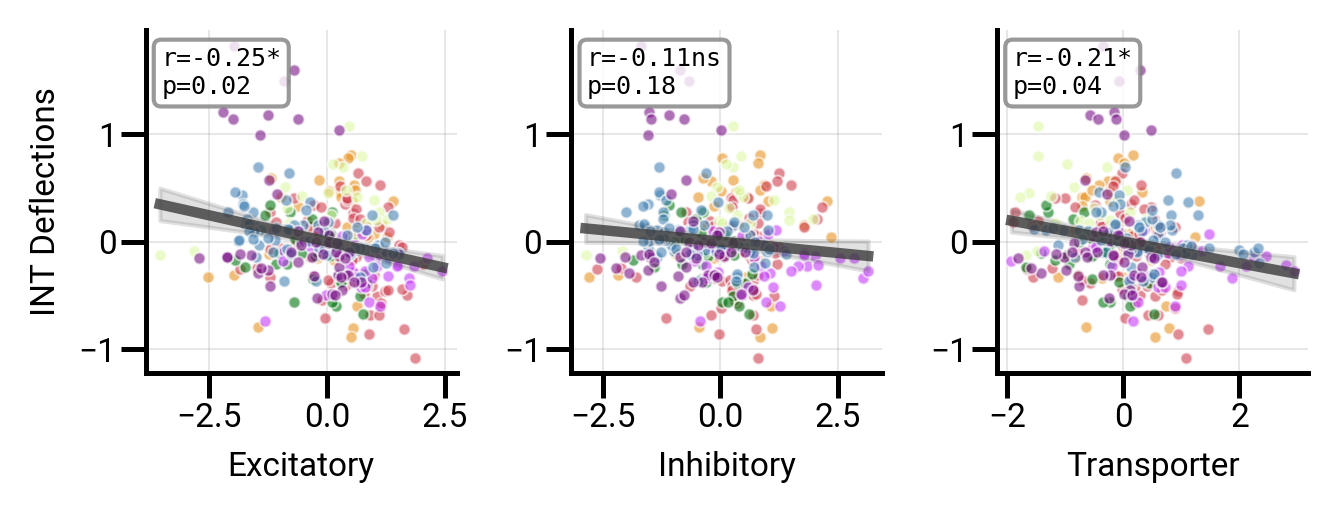

In [25]:
fig, axes = plt.subplots(nrows=1, ncols=len(plot_cols),
                         sharex=False, sharey=False,
                         figsize=(len(plot_cols)*1.5, 1.75), dpi=300)

for i, col in enumerate(plot_cols):
    x_glm = pd.Series(results[col]['feature_partial_resid'], name=col)
    y_glm = pd.Series(results[col]['task_partial_resid'], name='INT Deflections')
    plot_correlation(x_glm, y_glm, axes[i],
                     x_label=col.split('_')[1],
                     data_group=np.asarray(yeo_systems),
                     show_stats=True, fontsize=8, method='pearson',
                     size=8, cbar_label='Yeo Systems', show_colorbar=False, data_group_cmap='yeo7',
                     auto_polynomial=False, models_to_test=[1,], model_selection_metric='variance_explained',
                     custom_pvalue=null_pvals[col])
    if i != 0:
        axes[i].set_ylabel('')

for ax in axes:
    ax.tick_params(axis='y', which='major', pad=1)
    ax.tick_params(axis='x', which='major', pad=1)

fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, f'corr_intdelta_neurobio.svg'), bbox_inches='tight', dpi=300, transparent=True)
plt.show()


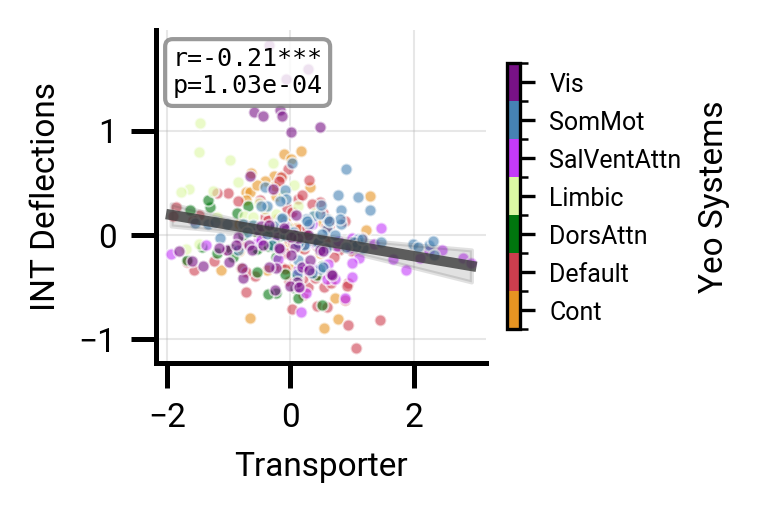

In [26]:
fig, axes = plt.subplots(nrows=1, ncols=1,
                         sharex=False, sharey=False,
                         figsize=(2.5, 1.75), dpi=300)

plot_correlation(x_glm, y_glm, axes,
                    x_label=col.split('_')[1],
                    data_group=np.asarray(yeo_systems),
                    show_stats=True, fontsize=8, method='pearson',
                    size=8, cbar_label='Yeo Systems', show_colorbar=True, data_group_cmap='yeo7',
                    auto_polynomial=False, models_to_test=[1,], model_selection_metric='variance_explained')
    
fig.tight_layout()
fig.savefig(os.path.join(nas_scratch_dir, f'corr_intdelta_neurobio_cbar.svg'), bbox_inches='tight', dpi=300, transparent=True)
plt.show()

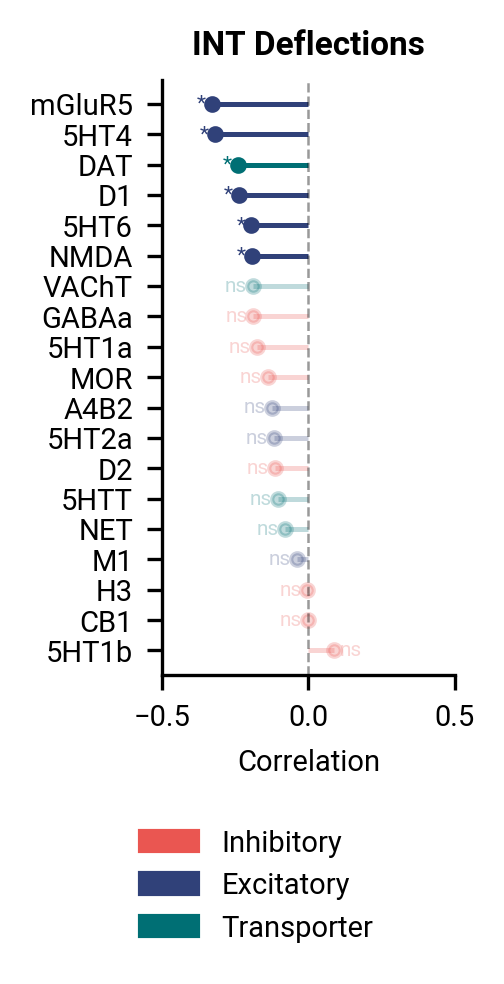

In [27]:
# Build correlation results from GLM partial residuals.
# P-values are from BrainSMASH spatial permutation tests (one-tailed).
df_results = pd.DataFrame(index=pet_categories.index, columns=['INT Deflections'], dtype=float)
df_pvals   = pd.DataFrame(index=pet_categories.index, columns=['INT Deflections'], dtype=float)

for col in pet_categories.index:
    x = results[col]['feature_partial_resid']
    y = results[col]['task_partial_resid']
    valid = ~(np.isnan(x) | np.isnan(y))
    corr, _ = sp.stats.pearsonr(x[valid], y[valid])
    df_results.loc[col, 'INT Deflections'] = corr
    df_pvals.loc[col,   'INT Deflections'] = null_pvals[col]

fig, axes = plot_faceted_lollipops(df_results, df_pvals, category_colors=my_colors,
                                   figsize=(1.75, 3.25), markersize=3, fontsize=8,
                                   show_legend=True, annotate_sig=True, nonsig_alpha=0.25)
df_results.to_csv(os.path.join(nas_scratch_dir, 'df_results_delta.csv'))
df_pvals.to_csv(os.path.join(nas_scratch_dir, 'df_pvals_delta.csv'))
fig.savefig(os.path.join(nas_scratch_dir, 'corr_intdelta_neurobio_lollipop.svg'), bbox_inches='tight', dpi=300, transparent=True)
plt.show()
